# NK recipes and interdependencies: K = 0, 1, 2

Question: can QCA recipes recover the NK interdependency matrix, and does the matrix shape the recipes?

**Symmetry reduction.** Two symmetries act on the policy space:
1. Relabeling the N elements. A landscape built on matrix A and one built on P A Pᵀ are the same up to relabeling, so we keep one matrix per isomorphism class.
2. Flipping the polarity of any element. Contributions are i.i.d. U(0,1), so flips leave the landscape distribution unchanged. Every recipe statistic below is invariant to flips, so no further reduction is needed.

What remains is one representative per class of directed graphs where every node has out-degree K.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N = 5             # elements
K_LIST = [0, 1, 2]
M = 200           # landscapes per matrix class
Q = 0.75          # calibration: a configuration is "in" the outcome set if f >= quantile Q
rng = np.random.default_rng(1)

X = ((np.arange(2**N)[:, None] >> np.arange(N)[::-1]) & 1).astype(np.int8)   # truth table rows
PERMS = np.array(list(itertools.permutations(range(N))))

## 1. Enumerate matrices and reduce by relabeling

In [2]:
def all_matrices(n, k):
    """Every n x n matrix with unit diagonal and exactly k off-diagonal ones per row."""
    row_opts = []
    for i in range(n):
        others = [j for j in range(n) if j != i]
        rows = []
        for S in itertools.combinations(others, k):
            r = np.zeros(n, np.int8); r[i] = 1; r[list(S)] = 1
            rows.append(r)
        row_opts.append(rows)
    return np.array([np.stack(rs) for rs in itertools.product(*row_opts)])

def canon_codes(A):
    """Canonical code of each matrix under simultaneous row and column relabeling."""
    w = 2 ** np.arange(A.shape[1] ** 2, dtype=np.int64)
    codes = np.stack([A[:, p][:, :, p].reshape(len(A), -1) @ w for p in PERMS])
    return codes.min(0)

def decode(code, n=N):
    return ((code >> np.arange(n * n)) & 1).reshape(n, n).astype(np.int8)

classes = []
for k in K_LIST:
    A = all_matrices(N, k)
    codes = canon_codes(A)
    uniq, counts = np.unique(codes, return_counts=True)
    for c, cnt in zip(uniq, counts):
        classes.append(dict(K=k, code=int(c), mat=decode(int(c)), orbit=int(cnt),
                            aut=len(PERMS) // int(cnt)))
    print(f"K={k}: {len(A)} labeled matrices -> {len(uniq)} classes")
cls = pd.DataFrame(classes)
cls["cid"] = [f"K{r.K}-{i}" for i, r in enumerate(cls.itertuples())]

K=0: 1 labeled matrices -> 1 classes
K=1: 1024 labeled matrices -> 13 classes


K=2: 7776 labeled matrices -> 79 classes


## 2. Landscapes and Walsh support

Each row i adds weight only on subsets of {i} ∪ N(i). The Walsh support is the down-closure of the row sets. The assert checks this on one draw.

In [3]:
def landscape(A, rng):
    """NK fitness of all 2^N configurations, Levinthal style: f = mean_i f_i(x restricted to row i)."""
    f = np.zeros(2**N)
    for i in range(N):
        cols = np.flatnonzero(A[i])
        idx = X[:, cols] @ (2 ** np.arange(len(cols))[::-1])
        f += rng.random(2 ** len(cols))[idx]
    return f / N

def walsh(f):
    """Walsh coefficients indexed by subset bitmask (bit N-1-i is element i, matching X)."""
    h = f.copy()
    s = 1
    while s < len(h):
        h = h.reshape(-1, 2, s)
        h = np.stack([h[:, 0] + h[:, 1], h[:, 0] - h[:, 1]], 1).reshape(-1)
        s *= 2
    return h / len(h)

def mask_of(cols):
    return int(sum(1 << (N - 1 - j) for j in cols))

def generic_support(A):
    """Down-closure of the row sets: the subsets a K-matrix allows to carry Walsh weight."""
    sup = set()
    for i in range(N):
        cols = np.flatnonzero(A[i])
        for r in range(len(cols) + 1):
            for S in itertools.combinations(cols, r):
                sup.add(mask_of(S))
    return frozenset(sup)

def canon_support(sup):
    """Canonical form of a support family under relabeling of elements."""
    best = None
    for p in PERMS:
        fam = tuple(sorted(mask_of([p[N - 1 - b] for b in range(N) if m >> b & 1]) for m in sup))
        best = fam if best is None or fam < best else best
    return best

# sanity: observed Walsh support equals the generic support for random draws
A0 = cls.mat[len(cls) - 1]
w = walsh(landscape(A0, rng))
assert set(np.flatnonzero(np.abs(w) > 1e-12)) == generic_support(A0)

## 3. QCA: calibration and prime implicants

Crisp calibration: a configuration is in the outcome set if f ≥ the Q quantile. The full truth table is observed, so there are no logical remainders. Recipes are all prime implicants, found by enumerating the 3^N cubes.

Features per landscape:
- `n_primes`, `mean_len`, `max_len`: recipe count and conjunction length.
- `nonunate`: elements that appear as both x and ~x across recipes. With K = 0, f ≥ c is a linear threshold function, so this must be 0.
- `pair_base_rate`: share of element pairs that truly interact (share a row set).
- `false_conj`: share of pairs joined in some recipe that do not interact.
- `recall`: share of interacting pairs that appear together in some recipe.

In [4]:
# Cubes (QCA terms): each element is 0, 1, or absent ("-")
CUBES = list(itertools.product([0, 1, None], repeat=N))
CMASK = np.array([sum(1 << (N - 1 - j) for j, v in enumerate(c) if v is not None) for c in CUBES])
CVAL = np.array([sum(1 << (N - 1 - j) for j, v in enumerate(c) if v == 1) for c in CUBES])
XINT = np.arange(2**N)
COVER = (XINT[None, :] & CMASK[:, None]) == CVAL[:, None]                 # cube x minterm
CONTAINS = (COVER[:, None, :] >= COVER[None, :, :]).all(-1) & (CMASK[:, None] != CMASK[None, :])
NLIT = np.array([bin(m).count("1") for m in CMASK])

def primes(on):
    imp = ~(COVER & ~on[None, :]).any(1)
    bigger_imp = (CONTAINS & imp[:, None]).any(0)     # some implicant strictly contains this cube
    return np.flatnonzero(imp & ~bigger_imp)

def recipe_features(f, A):
    on = f >= np.quantile(f, Q)
    P = primes(on)
    lits = [[(j, CUBES[c][j]) for j in range(N) if CUBES[c][j] is not None] for c in P]
    pol = {}
    for L in lits:
        for j, v in L: pol.setdefault(j, set()).add(v)
    nonunate = sum(len(v) == 2 for v in pol.values())
    conj_pairs = {tuple(sorted((a[0], b[0]))) for L in lits for a, b in itertools.combinations(L, 2)}
    true_pairs = {tuple(sorted(p)) for i in range(N) for p in itertools.combinations(np.flatnonzero(A[i]), 2)}
    return dict(n_primes=len(P), mean_len=np.mean(NLIT[P]), max_len=NLIT[P].max(),
                nonunate=nonunate,
                pair_base_rate=len(true_pairs) / (N * (N - 1) / 2),
                false_conj=len(conj_pairs - true_pairs) / max(len(conj_pairs), 1),
                recall=len(conj_pairs & true_pairs) / max(len(true_pairs), 1) if true_pairs else np.nan)

## 4. Identifiability with full information

Even with the exact real-valued f, only the Walsh support is observable. Matrix classes with the same support (up to relabeling) cannot be told apart. `lost` counts the classes that merge.

In [5]:
# Full information: which matrix classes share a Walsh support (indistinguishable even from exact f)?
cls["support"] = [canon_support(generic_support(A)) for A in cls.mat]
ident = (cls.groupby("K")
            .agg(classes=("cid", "size"), support_classes=("support", "nunique"))
            .assign(lost=lambda d: d.classes - d.support_classes))
ident

,classes,support_classes,lost
K,,,
0,1,1,0
1,13,10,3
2,79,15,64


## 5. Simulate recipes

In [6]:
rows = []
for r in cls.itertuples():
    for m in range(M):
        f = landscape(r.mat, rng)
        rows.append(dict(K=r.K, cid=r.cid, **recipe_features(f, r.mat)))
sim = pd.DataFrame(rows)
sim.groupby("K")[["n_primes", "mean_len", "max_len", "nonunate", "pair_base_rate", "false_conj", "recall"]].mean().round(3)

,n_primes,mean_len,max_len,nonunate,pair_base_rate,false_conj,recall
K,,,,,,,
0,2.885,2.874,3.165,0.000,0.000,1.000,NaN
1,3.905,3.379,3.772,1.820,0.431,0.516,0.875
2,4.776,3.761,4.234,3.342,0.854,0.135,0.961


## 6. Can recipes identify the matrix?

Nearest-centroid classifier on standardized recipe features. Half the landscapes train it, half test it.

In [7]:
# Can recipes identify the matrix class? Nearest centroid on standardized recipe features, half split.
FEATS = ["n_primes", "mean_len", "max_len", "nonunate", "false_conj"]

def centroid_accuracy(df, label):
    idx = rng.permutation(len(df)); tr, te = df.iloc[idx[::2]], df.iloc[idx[1::2]]
    mu, sd = tr[FEATS].mean(), tr[FEATS].std().replace(0, 1)
    C = ((tr[FEATS] - mu) / sd).groupby(tr[label]).mean()
    Z = ((te[FEATS] - mu) / sd).to_numpy()
    pred = C.index[((Z[:, None, :] - C.to_numpy()[None]) ** 2).sum(-1).argmin(1)]
    return (pred == te[label].to_numpy()).mean(), 1 / df[label].nunique()

out = {"K from recipes": centroid_accuracy(sim, "K")}
for k in [1, 2]:
    out[f"class | K={k}"] = centroid_accuracy(sim[sim.K == k], "cid")
pd.DataFrame(out, index=["accuracy", "chance"]).T.round(3)

,accuracy,chance
K from recipes,0.898,0.333
class | K=1,0.168,0.077
class | K=2,0.053,0.013


## 7. Distributions

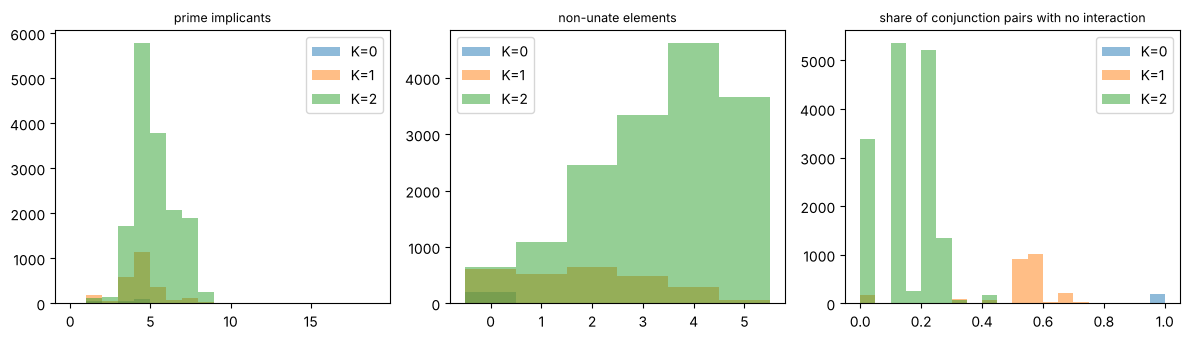

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for k in K_LIST:
    d = sim[sim.K == k]
    ax[0].hist(d.n_primes, bins=range(0, 20), alpha=0.5, label=f"K={k}")
    ax[1].hist(d.nonunate, bins=np.arange(-0.5, N + 1), alpha=0.5, label=f"K={k}")
    ax[2].hist(d.false_conj, bins=np.linspace(0, 1, 21), alpha=0.5, label=f"K={k}")
for a, t in zip(ax, ["prime implicants", "non-unate elements", "share of conjunction pairs with no interaction"]):
    a.set_title(t, fontsize=9); a.legend()
plt.tight_layout(); plt.show()

## 8. Do recipes match local maxima?

Local maxima use one-flip neighbourhoods. For each calibration Q:
- `peaks`, `peaks_on`: all local maxima, and those inside the outcome set (QCA cannot see the rest).
- `primes`, `cover`: all prime implicants, and a greedy minimal cover (the QCA solution; greedy, so it may not be minimum).
- `primes_0pk`, `primes_1pk`, `cover_1pk`: share of recipes holding no peak or exactly one.
- `peaks_isolated`: share of visible peaks that some recipe holds alone.
- `gmax_in_widest`: the global maximum lies in a recipe with the fewest conditions.

In [9]:
NEIGH = XINT[:, None] ^ (1 << np.arange(N))[None, :]           # one-flip neighbours

def peak_features(f, q):
    on = f >= np.quantile(f, q)
    peaks = (f[:, None] > f[NEIGH]).all(1)
    P = primes(on)
    per_prime = (COVER[P] & peaks[None, :]).sum(1)              # peaks inside each recipe
    # minimal cover (QCA solution): essential primes, then greedy
    left, cover = on.copy(), []
    while left.any():
        c = P[(COVER[P] & left).sum(1).argmax()]
        cover.append(c); left &= ~COVER[c]
    per_cov = (COVER[cover] & peaks[None, :]).sum(1)
    pk = np.flatnonzero(peaks & on)
    own = [(COVER[P][:, p] & (per_prime == 1)).any() for p in pk]   # some recipe isolates this peak
    g = f.argmax()
    widest = P[NLIT[P] == NLIT[P].min()]
    return dict(peaks=peaks.sum(), peaks_on=len(pk), primes=len(P), cover=len(cover),
                primes_0pk=(per_prime == 0).mean(), primes_1pk=(per_prime == 1).mean(),
                cover_1pk=(per_cov == 1).mean(),
                peaks_isolated=np.mean(own),
                gmax_in_widest=COVER[widest, g].any())

rows = []
for q in [0.5, 0.75, 0.9]:
    for r in cls.itertuples():
        for m in range(50):
            rows.append(dict(K=r.K, Q=q, **peak_features(landscape(r.mat, rng), q)))
pk = pd.DataFrame(rows)
pk.groupby(["Q", "K"]).mean(numeric_only=True).round(2)

peaks  peaks_on  primes  cover  primes_0pk  primes_1pk  cover_1pk  \
Q    K                                                                      
0.50 0   1.00      1.00    3.94   3.94        0.00        1.00       1.00   
     1   1.90      1.90    6.02   4.97        0.21        0.69       0.70   
     2   2.84      2.83    7.96   5.74        0.28        0.63       0.65   
0.75 0   1.00      1.00    3.08   3.08        0.00        1.00       1.00   
     1   1.89      1.79    3.83   3.44        0.12        0.82       0.83   
     2   2.83      2.61    4.78   4.08        0.19        0.76       0.78   
0.90 0   1.00      1.00    1.72   1.72        0.00        1.00       1.00   
     1   1.85      1.54    2.35   2.20        0.05        0.93       0.92   
     2   2.88      2.10    2.69   2.59        0.07        0.91       0.91   

        peaks_isolated  gmax_in_widest  
Q    K                                  
0.50 0            1.00            1.00  
     1            0.96            0.98  
     2            0.93            0.90  
0.75 0            1.00            1.00  
     1            0.96            0.95  
     2            0.96            0.87  
0.90 0            1.00            1.00  
     1            0.98            0.97  
     2            0.98            0.88